# 36 — Generalisation from O1 to O2 and O3

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 41. Nine new H1 chunks of 4096 s (three each in O2, O3a, O3b; `download_runs.py`, ≥ 2000 s from every catalogued event) are processed with the *unchanged* pipeline: whitening with the chunk's own median-Welch PSD, one-second windows, band 30–500 Hz. Three questions:

1. **Does the O1 calibration transfer?** The observed FAP of the O1 thresholds (validation noise, FAP 10⁻² and 10⁻³) on the noise of O2/O3, for the sine-Gaussian bank and the CNN trained on O1 only.
2. **How does the noise change?** PSD level in the band, share of glitchy windows, tail of the bank statistic.
3. **Does the sensitivity transfer?** ρ₅₀ (sine-Gaussian, pulse, chirp) of the bank and of the O1 CNN with (a) the O1 threshold and (b) the threshold set on the noise of the same run.

**What it does not do.** The CNN is not retrained or fine-tuned on O2/O3; three chunks per run (≈ 12 000 windows) limit the background to FAP ≳ 10⁻³; the injection prior is that of the project, not tuned to each run; no data-quality cuts.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, json, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
rng = np.random.default_rng(36)
RUNS = g.load_json("runs_chunks.json")
def whiten(c):
    fn = os.path.join(g.CACHE, f"win_{c['run']}_{c['gps_start']}.npz")
    if os.path.exists(fn): d = np.load(fn); return {k: d[k] for k in d.files}
    x = np.load(os.path.join(g.CACHE, "raw", c["file"])); v, f, S = g.whiten_chunk(x); w = g.make_windows(v); out = dict(v=w, S1=g.psd_1hz(f, S), f_psd=f, S=S); np.savez_compressed(fn, **out); return out
W = {(c["run"], c["gps_start"]): whiten(c) for c in RUNS}
print({k: v["v"].shape for k, v in W.items()})
nets = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in range(5)]
cnn = lambda v: np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in nets], 0)
O1 = {c: g.load_chunk(c) for c in range(len(g.chunks()))}
vva, cva, _ = g.load_split("val"); VAL = {"bank": np.load(os.path.join(g.CACHE, "scan03_val.npz"))["rho2"], "cnn": cnn(vva)}
THR = {far: {k: g.threshold_at_far(v, far) for k, v in VAL.items()} for far in (1e-2, 1e-3)}

{('O2', 1171091456): (4056, 1024), ('O2', 1175318528): (4056, 1024), ('O2', 1182334976): (4056, 1024), ('O3a', 1242619904): (4056, 1024), ('O3a', 1246408704): (4056, 1024), ('O3a', 1250336768): (4056, 1024), ('O3b', 1259868160): (4056, 1024), ('O3b', 1263034368): (4056, 1024), ('O3b', 1266307072): (4056, 1024)}


## 1-2. Calibration and noise properties

In [2]:
BK = {k: g.SGBank(w["S1"]) for k, w in W.items()}; STAT = {k: dict(bank=BK[k].scan(g.to_bins(w["v"]))["rho2"], cnn=cnn(w["v"])) for k, w in W.items()}
ref_psd = np.median(np.stack([O1[c]["S1"] for c in O1]), 0); band = g.BAND
rows = []
for (run, gps), s in STAT.items():
    w = W[(run, gps)]; q = lambda x: float(np.quantile(x, .999))
    rows.append(dict(run=run, gps=gps, windows=len(w["v"]), asd_rel_O1=float(np.sqrt(np.mean(w["S1"][band] / ref_psd[band]))), std_v=float(w["v"].std()), kurtosis_excess=float(((w["v"] - w["v"].mean()) ** 4).mean() / w["v"].var() ** 2 - 3),
                     bank_q999=q(s["bank"]), **{f"FAP_bank_O1thr_{far:g}": float((s["bank"] > THR[far]["bank"]).mean()) for far in THR}, **{f"FAP_cnn_O1thr_{far:g}": float((s["cnn"] > THR[far]["cnn"]).mean()) for far in THR}))
CAL = pd.DataFrame(rows); CAL.round(4)

,run,gps,windows,asd_rel_O1,std_v,kurtosis_excess,bank_q999,FAP_bank_O1thr_0.01,FAP_bank_O1thr_0.001,FAP_cnn_O1thr_0.01,FAP_cnn_O1thr_0.001
0,O2,1171091456,4056,0.9139,0.9765,175.5506,75.8945,0.0224,0.0027,0.0185,0.0025
1,O2,1175318528,4056,0.8996,0.9583,0.4233,45.4083,0.0086,0.0010,0.0153,0.0022
2,O2,1182334976,4056,0.9150,0.9566,0.1009,32.0798,0.0064,0.0002,0.0148,0.0012
3,O3a,1242619904,4056,0.6517,3.5077,848638.0000,13674.8034,0.0108,0.0027,0.0212,0.0017
4,O3a,1246408704,4056,0.6278,1.5312,648581.8750,51.8738,0.0086,0.0012,0.0178,0.0025
5,O3a,1250336768,4056,0.6697,4.3209,122954.2969,706849.7813,0.0298,0.0081,0.0229,0.0057
6,O3b,1259868160,4056,0.6275,1.2771,18914.7871,606.3077,0.0106,0.0020,0.0168,0.0015
7,O3b,1263034368,4056,0.6000,3.3478,389013.1562,2852.2873,0.0096,0.0035,0.0143,0.0010
8,O3b,1266307072,4056,0.5943,1.2996,203575.1875,88.5890,0.0062,0.0012,0.0136,0.0010


In [3]:
print("observed FAP of the O1 thresholds, pooled per run (nominal 0.01 / 0.001):")
G = CAL.groupby("run").agg(asd=("asd_rel_O1", "mean"), bank_1e2=("FAP_bank_O1thr_0.01", "mean"), bank_1e3=("FAP_bank_O1thr_0.001", "mean"), cnn_1e2=("FAP_cnn_O1thr_0.01", "mean"), cnn_1e3=("FAP_cnn_O1thr_0.001", "mean"), kurt=("kurtosis_excess", "mean")); G.round(4)

observed FAP of the O1 thresholds, pooled per run (nominal 0.01 / 0.001):


,asd,bank_1e2,bank_1e3,cnn_1e2,cnn_1e3,kurt
run,,,,,,
O2,0.9095,0.0125,0.0013,0.0162,0.0020,58.6916
O3a,0.6497,0.0164,0.0040,0.0206,0.0033,540058.0573
O3b,0.6073,0.0088,0.0022,0.0149,0.0012,203834.3770


## 3. Sensitivity

In [4]:
SNR = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; NINJ = 150; fn = os.path.join(g.CACHE, "stats36.pkl")
if os.path.exists(fn): INJ = pickle.load(open(fn, "rb"))
else:
    INJ = {}
    for key, w in W.items():
        for kind in g.MORPHS:
            for s in SNR:
                i = rng.choice(len(w["v"]), NINJ, replace=False); ser, _, _ = g.inject(w["v"][i], kind, float(s), rng, w["S1"]); INJ[(key, kind, s)] = dict(bank=BK[key].scan(g.to_bins(ser))["rho2"], cnn=cnn(ser))
    pickle.dump(INJ, open(fn, "wb"))
rows = []
for run in ("O2", "O3a", "O3b"):
    keys = [k for k in W if k[0] == run]; own = {d: np.concatenate([STAT[k][d] for k in keys]) for d in ("bank", "cnn")}
    for det in ("bank", "cnn"):
        for far in (1e-2, 1e-3):
            for mode, thr in (("O1 threshold", THR[far][det]), ("own-run threshold", g.threshold_at_far(own[det], far))):
                r = []
                for kind in g.MORPHS:
                    e = [float(np.mean(np.concatenate([INJ[(k, kind, s)][det] for k in keys]) > thr)) for s in SNR]; r.append(g.snr_level(e, SNR, .5))
                rows.append(dict(run=run, detector=det, FAP=far, threshold=mode, rho50=float(np.mean([np.nan_to_num(x, nan=16) for x in r]))))
SENS = pd.DataFrame(rows); P = SENS[SENS.FAP == 1e-2].pivot_table(index=["detector", "threshold"], columns="run", values="rho50"); P["O1 (nb07/06 val)"] = [5.58, 5.58, 4.31, 4.31][:len(P)] if False else np.nan; P.round(2)

run                           O2   O3a   O3b  O1 (nb07/06 val)
detector threshold                                            
bank     O1 threshold       5.55  5.55  5.58               NaN
         own-run threshold  5.63  5.90  5.53               NaN
cnn      O1 threshold       3.69  3.87  3.86               NaN
         own-run threshold  4.09  4.54  4.25               NaN

FAP 1e-3:


run                           O2    O3a    O3b
detector threshold                            
bank     O1 threshold       7.75   7.76   7.69
         own-run threshold  8.58  16.00  16.00
cnn      O1 threshold       5.23   5.33   5.35
         own-run threshold  5.43   6.24   5.46

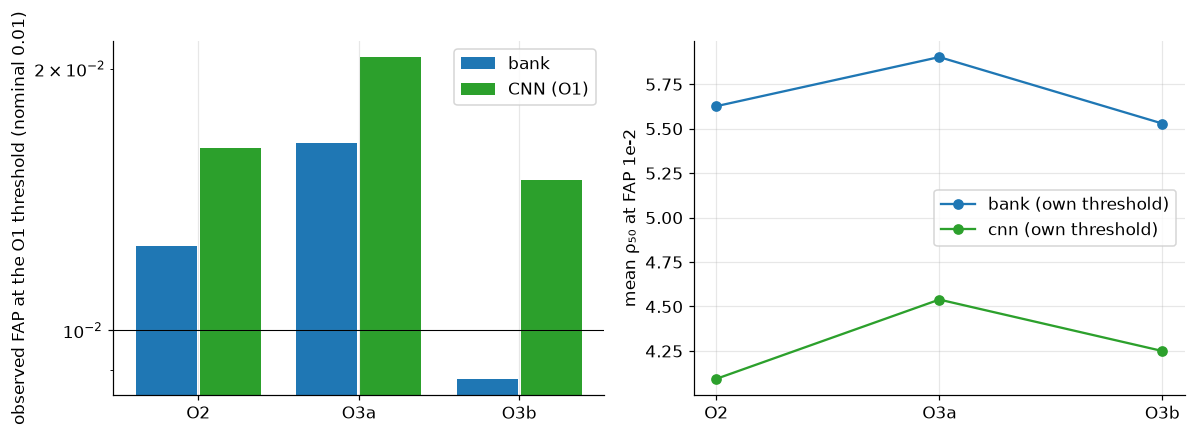

In [5]:
print("FAP 1e-3:"); display(SENS[SENS.FAP == 1e-3].pivot_table(index=["detector", "threshold"], columns="run", values="rho50").round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(np.arange(len(G)) - .2, G.bank_1e2, .38, label="bank", color=g.COLORS["freq"]); ax[0].bar(np.arange(len(G)) + .2, G.cnn_1e2, .38, label="CNN (O1)", color="C2"); ax[0].axhline(.01, color="k", lw=.7); ax[0].set_xticks(range(len(G))); ax[0].set_xticklabels(G.index); ax[0].set_yscale("log"); ax[0].set_ylabel("observed FAP at the O1 threshold (nominal 0.01)"); ax[0].legend()
for det, c in (("bank", g.COLORS["freq"]), ("cnn", "C2")):
    s = SENS[(SENS.FAP == 1e-2) & (SENS.detector == det) & (SENS.threshold == "own-run threshold")]; ax[1].plot(s.run, s.rho50, "o-", color=c, label=det + " (own threshold)")
ax[1].set_ylabel("mean ρ₅₀ at FAP 1e-2"); ax[1].legend(); fig.tight_layout(); g.savefig(fig, "fig36_o2_o3"); plt.show()
g.save_json(dict(chunks=CAL.to_dict("records"), per_run=G.reset_index().to_dict("records"), sensitivity=SENS.to_dict("records")), "36_summary.json")

## Output and next step

`results/36_summary.json`, `figures/fig36_o2_o3`, `results/runs_chunks.json`. Next: the remaining physical regimes of the backlog (low masses, high frequencies, NSBH) and the final slides.